# Name: What Makes a Google Play App Successful?

Goal: Explore how category, type (free or paid), price, size, and last
update date relate to app installs and ratings, to help developers
decide what kind of new app to build.

## Asking Questions
Q1: Which category has the highest average rating?

Q2: Do free apps have more installs than paid apps on average?

Q3: Do apps updated more recently have higher average ratings?

Q4: Which category has the highest percentage of positive reviews?

Q5: Is there a relationship between app size and number of installs?

## Data Wrangling
### Gather


First, we import the libraries we will use throughout the project: NumPy, Pandas, Matplotlib and Seaborn.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



Then, we load the apps and reviews CSV files using relative paths, so the notebook runs on any computer.

In [2]:
df_apps_raw = pd.read_csv('data/raw/googleplaystore.csv')
df_reviews_raw = pd.read_csv('data/raw/googleplaystore_user_reviews.csv')


### Field Description

**Apps table (googleplaystore.csv)**
- `App`: the app name
- `Category`: the main category of the app (e.g. ART_AND_DESIGN)
- `Rating`: the average user rating, from 1 to 5
- `Reviews`: how many reviews the app has (a number)
- `Size`: the app size (e.g. 19M means 19 MB)
- `Installs`: about how many times the app was downloaded (e.g. 10,000+ means more than 10,000)
- `Type`: Free or Paid
- `Price`: how much the app costs if it's paid
- `Content Rating`: the age group the app is for (e.g. Everyone, Teen)
- `Genres`: one or more genres, separated by `;`
- `Last Updated`: the date of the last update
- `Current Ver`: the current version of the app
- `Android Ver`: the minimum Android version needed

**Reviews table (googleplaystore_user_reviews.csv)**
- `App`: the app name (links to the apps table)
- `Translated_Review`: the user's review text, translated to English
- `Sentiment`: Positive, Negative or Neutral
- `Sentiment_Polarity`: how positive the review is, from -1 (negative) to 1 (positive)
- `Sentiment_Subjectivity`: how personal the review is, from 0 (fact) to 1 (opinion)

### Assess

In [3]:
df_apps_raw.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


We also look at the first 5 rows of the reviews table.

In [4]:
df_reviews_raw.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


We check how many rows and columns each table has.

In [5]:
print('Apps table shape:')
print(df_apps_raw.shape)

Apps table shape:
(10841, 13)


In [6]:
print('Reviews table shape:')
print(df_reviews_raw.shape)

Reviews table shape:
(64295, 5)


info() shows the type of each column and how many values are not empty.

In [7]:
df_apps_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [8]:
df_reviews_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  str    
 1   Translated_Review       37427 non-null  str    
 2   Sentiment               37432 non-null  str    
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), str(3)
memory usage: 2.5 MB


We count the missing values in each column.

In [9]:
df_apps_raw.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [10]:
df_reviews_raw.isnull().sum()

App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

We count the fully duplicated rows, then the duplicated app names.

In [11]:
print(df_apps_raw.duplicated().sum())


483


In [12]:
print(df_apps_raw['App'].duplicated().sum())

1181


We count the fully duplicated rows in the reviews table.

In [13]:
print(df_reviews_raw.duplicated().sum())

33616


describe() gives statistics for the number columns only.

In [14]:
df_apps_raw.describe()

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


In [15]:
df_reviews_raw.describe()

,Sentiment_Polarity,Sentiment_Subjectivity
count,37432.000000,37432.000000
mean,0.182146,0.492704
std,0.351301,0.259949
min,-1.000000,0.000000
25%,0.000000,0.357143
50%,0.150000,0.514286
75%,0.400000,0.650000
max,1.000000,1.000000


The max Rating is 19, but ratings go from 1 to 5, so we look for ratings above 5.

In [16]:
df_apps_raw[df_apps_raw['Rating']>5]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


We count the values of Type and Sentiment to find strange values.

In [17]:
df_apps_raw['Type'].value_counts()

Type
Free    10039
Paid      800
0           1
Name: count, dtype: int64

In [18]:
df_reviews_raw['Sentiment'].value_counts()

Sentiment
Positive    23998
Negative     8271
Neutral      5163
Name: count, dtype: int64

### Data Issues
- One broken row (10472): its values moved to the wrong columns
- Missing values: Rating (1,474), Current Ver (8), Android Ver (3), Type (1), Content Rating (1)
- Duplicate rows (483) and duplicate app names (1,181)
- Number columns stored as text: Reviews, Size, Installs, Price
- Date stored as text: Last Updated
- Columns we don't need: Android Ver, Current Ver
- Column names have spaces
- In reviews: 26,868 rows without text and 33,616 duplicate rows

### Clean

We make working copies so the original data stays safe.

In [19]:
df_apps = df_apps_raw.copy()
df_reviews = df_reviews_raw.copy()

We drop row 10472 because its Category value is missing, so all its values moved to the wrong place. We can't fix it safely, and it is only one row out of 10,841.

In [20]:
df_apps = df_apps.drop(index = 10472)
print(df_apps['Rating'].max())

5.0


We count the missing values again after dropping the broken row.

In [21]:
print(df_apps.isnull().sum())

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64


We keep the missing Rating values as NaN. Filling them would make fake ratings, and dropping them would lose other useful columns. Pandas ignores NaN when it calculates the mean.

One app has no Type. We look at this row to see if we can find its type from another column.

In [22]:
df_apps[df_apps['Type'].isnull()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


We fill the missing Type with "Free", because this app's Price is 0.

In [23]:
df_apps['Type'] = df_apps['Type'].fillna('Free')
print(df_apps['Type'].value_counts(dropna=False))

Type
Free    10040
Paid      800
Name: count, dtype: int64


We drop 483 fully duplicated rows because they count the same app more than once.

In [24]:
print('Before:', df_apps.shape)
df_apps = df_apps.drop_duplicates()
print('After:', df_apps.shape)
print('Duplicated rows left:', df_apps.duplicated().sum())

Before: (10840, 13)


After: (10357, 13)
Duplicated rows left: 0


We convert Reviews from text to integer. It was text only because of the broken row we dropped.

In [25]:
df_apps['Reviews'] = df_apps['Reviews'].astype('int64')
print(df_apps['Reviews'].dtype)

int64


Some apps appear more than once with different values. We keep the row with the most Reviews, because it is the most recent one.

In [26]:
print('Duplicated app names before:', df_apps['App'].duplicated().sum())
df_apps = df_apps.sort_values('Reviews', ascending=False)
df_apps = df_apps.drop_duplicates(subset='App', keep='first')
print('Duplicated app names after:', df_apps['App'].duplicated().sum())
print('Shape:', df_apps.shape)

Duplicated app names before: 698
Duplicated app names after: 0
Shape: (9659, 13)


In the reviews table, we drop rows with no Sentiment, because they can't help answer Q4. We keep the 5 rows that have a Sentiment but no text, since Q4 only uses Sentiment.


In [27]:
print('Before:', df_reviews.shape)
df_reviews = df_reviews.dropna(subset=['Sentiment'])
print('After:', df_reviews.shape)
print(df_reviews.isnull().sum())

Before: (64295, 5)


After: (37432, 5)
App                       0
Translated_Review         5
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64


We check the duplicated reviews and look at some of them before we decide.

In [28]:
print('Duplicated review rows:', df_reviews.duplicated().sum())
df_reviews[df_reviews.duplicated()].head(10)

Duplicated review rows: 7735


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
78,10 Best Foods for You,Good,Positive,0.70,0.600000
79,10 Best Foods for You,Good,Positive,0.70,0.600000
100,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
101,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
103,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
104,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
105,10 Best Foods for You,Best way,Positive,1.00,0.300000
106,10 Best Foods for You,Amazing,Positive,0.60,0.900000
108,10 Best Foods for You,"Looking forward app,",Neutral,0.00,0.000000
109,10 Best Foods for You,It helpful site ! It help foods get !,Neutral,0.00,0.000000


Many reviews appear twice in the same order (for example, rows 100 to 109 repeat rows 0 to 9), so they were collected twice by mistake. We drop all duplicated reviews so they are not counted twice in Q4.

In [29]:
print('Before:', df_reviews.shape)
df_reviews = df_reviews.drop_duplicates()
print('After:', df_reviews.shape)

Before: (37432, 5)
After: (29697, 5)


We convert Last Updated from text to a real date, so we can sort it and get the year for Q3.

In [30]:
df_apps['Last Updated'] = pd.to_datetime(df_apps['Last Updated'], format='%B %d, %Y')
print(df_apps['Last Updated'].dtype)
print('Oldest update:', df_apps['Last Updated'].min())
print('Newest update:', df_apps['Last Updated'].max())


datetime64[us]
Oldest update: 2010-05-21 00:00:00
Newest update: 2018-08-08 00:00:00


We remove "," and "+" from Installs and convert it to integer. Note: each value is a minimum (10000 means "more than 10,000").

In [31]:
df_apps['Installs'] = df_apps['Installs'].str.replace(',', '', regex=False)
df_apps['Installs'] = df_apps['Installs'].str.replace('+', '', regex=False)
df_apps['Installs'] = df_apps['Installs'].astype('int64')
print(df_apps['Installs'].dtype)
print(df_apps['Installs'].value_counts().sort_index())

int64
Installs
0               15
1               67
5               82
10             385
50             204
100            709
500            328
1000           887
5000           468
10000         1030
50000          469
100000        1113
500000         504
1000000       1417
5000000        607
10000000       937
50000000       204
100000000      189
500000000       24
1000000000      20
Name: count, dtype: int64


We remove "$" from Price and convert it to a decimal number, because prices like 4.99 have cents.


In [32]:
df_apps['Price'] = df_apps['Price'].str.replace('$', '', regex=False).astype('float64')
print(df_apps['Price'].dtype)
print(df_apps['Price'].describe())

float64
count    9659.000000
mean        1.097231
std        16.851618
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       400.000000
Name: Price, dtype: float64


#### Outliers in Price
First, we look at the most expensive apps (price above $100).

In [33]:
df_apps[df_apps['Price'] > 100]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
5351,I am rich,LIFESTYLE,3.8,3547,1.8M,100000,Paid,399.99,Everyone,Lifestyle,2018-01-12,2.0,4.0.3 and up
5356,I Am Rich Premium,FINANCE,4.1,1867,4.7M,50000,Paid,399.99,Everyone,Finance,2017-11-12,1.6,4.0 and up
5354,I am Rich Plus,FAMILY,4.0,856,8.7M,10000,Paid,399.99,Everyone,Entertainment,2018-05-19,3.0,4.4 and up
4362,💎 I'm rich,LIFESTYLE,3.8,718,26M,10000,Paid,399.99,Everyone,Lifestyle,2018-03-11,1.0.0,4.4 and up
5359,I am rich(premium),FINANCE,3.5,472,965k,5000,Paid,399.99,Everyone,Finance,2017-05-01,3.4,4.4 and up
5355,I am rich VIP,LIFESTYLE,3.8,411,2.6M,10000,Paid,299.99,Everyone,Lifestyle,2018-07-21,1.1.1,4.3 and up
4367,I'm Rich - Trump Edition,LIFESTYLE,3.6,275,7.3M,10000,Paid,400.00,Everyone,Lifestyle,2018-05-03,1.0.1,4.1 and up
5366,I Am Rich,FAMILY,3.6,217,4.9M,10000,Paid,389.99,Everyone,Entertainment,2018-06-22,1.5,4.2 and up
5362,I Am Rich Pro,FAMILY,4.4,201,2.7M,5000,Paid,399.99,Everyone,Entertainment,2017-05-30,1.54,1.6 and up
5369,I am Rich,FINANCE,4.3,180,3.8M,5000,Paid,399.99,Everyone,Finance,2018-03-22,1.0,4.2 and up


Most of these apps are "I am rich" apps that cost about $400. They are real apps on Google Play, not data errors.
Next, we check the IQR method on Price.

In [34]:
q1 = df_apps['Price'].quantile(0.25)
q3 = df_apps['Price'].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
print('Q1:', q1, '| Q3:', q3, '| IQR:', iqr, '| Upper limit:', upper_limit)
print('Apps above the limit:', (df_apps['Price'] > upper_limit).sum())

Q1: 0.0 | Q3: 0.0 | IQR: 0.0 | Upper limit: 0.0
Apps above the limit: 754


The upper limit is 0, because more than 75% of apps are free. To test it, we apply clip on a separate copy of Price, without changing df_apps.

In [35]:
price_clipped = df_apps['Price'].clip(upper=upper_limit)
print('Paid apps with price > 0 (original):', (df_apps['Price'] > 0).sum())
print('Paid apps with price > 0 (after clip):', (price_clipped > 0).sum())
print('Max price (original):', df_apps['Price'].max())
print('Max price (after clip):', price_clipped.max())

Paid apps with price > 0 (original): 754
Paid apps with price > 0 (after clip): 0


Max price (original): 400.0
Max price (after clip): 0.0


**Decision:** After clipping, every paid app has a price of 0, so clipping would destroy the Price column. We keep all prices as they are, and we will use the median when we compare prices.

#### Outliers in Reviews and Installs
Reviews and Installs also have very big values. We look at the apps with the most reviews to see if they are real.

In [36]:
df_apps.sort_values('Reviews', ascending=False)[['App', 'Category', 'Reviews', 'Installs']].head(5)

,App,Category,Reviews,Installs
2544,Facebook,SOCIAL,78158306,1000000000
336,WhatsApp Messenger,COMMUNICATION,69119316,1000000000
2604,Instagram,SOCIAL,66577446,1000000000
382,Messenger – Text and Video Chat for Free,COMMUNICATION,56646578,1000000000
1879,Clash of Clans,GAME,44893888,100000000


**Decision:** The biggest values belong to famous apps like Facebook and WhatsApp, so they are real and we keep them. Because these columns are very skewed, we will use the median (not only the mean) in the analysis.

#### Converting Size to MB
Size has values in MB ("19M"), in KB ("965k"), and "Varies with device". We write a function that converts one value to MB. "Varies with device" becomes NaN, because we don't know the real size.

In [37]:
# Convert one Size value to MB
def size_to_mb(size):
    if size == 'Varies with device':
        return np.nan                     # unknown size
    if 'M' in size:
        number = size.replace('M', '')    # '19M' -> '19'
        return float(number)              # '19' -> 19.0
    if 'k' in size:
        number = size.replace('k', '')    # '965k' -> '965'
        return float(number) / 1024       # KB -> MB

Now we apply the function to every value in Size, and check that the number of missing values equals the number of "Varies with device" values.

In [38]:
print('Varies with device:', (df_apps['Size'] == 'Varies with device').sum())
df_apps['Size'] = df_apps['Size'].apply(size_to_mb)
print('Missing Size after:', df_apps['Size'].isnull().sum())
print(df_apps['Size'].describe())

Varies with device: 1228
Missing Size after: 1228


count    8431.000000
mean       20.398075
std        21.828959
min         0.008301
25%         4.600000
50%        12.000000
75%        28.000000
max       100.000000
Name: Size, dtype: float64


#### Renaming and dropping columns
We rename the columns to lowercase names without spaces, so they are easier to write in code. We also rename Size to size_mb to show its unit.

In [39]:
df_apps = df_apps.rename(columns={
    'App': 'app',
    'Category': 'category',
    'Rating': 'rating',
    'Reviews': 'reviews',
    'Size': 'size_mb',
    'Installs': 'installs',
    'Type': 'type',
    'Price': 'price',
    'Content Rating': 'content_rating',
    'Genres': 'genres',
    'Last Updated': 'last_updated',
    'Current Ver': 'current_ver',
    'Android Ver': 'android_ver'
})

df_reviews = df_reviews.rename(columns={
    'App': 'app',
    'Translated_Review': 'review_text',
    'Sentiment': 'sentiment',
    'Sentiment_Polarity': 'polarity',
    'Sentiment_Subjectivity': 'subjectivity'
})

print(df_apps.columns.tolist())
print(df_reviews.columns.tolist())

['app', 'category', 'rating', 'reviews', 'size_mb', 'installs', 'type', 'price', 'content_rating', 'genres', 'last_updated', 'current_ver', 'android_ver']
['app', 'review_text', 'sentiment', 'polarity', 'subjectivity']


We drop current_ver and android_ver because none of our five questions uses them.

In [40]:
df_apps = df_apps.drop(columns=['current_ver', 'android_ver'])
print(df_apps.shape)

(9659, 11)


#### New columns
- update_year: the year of the last update, for Q3.
- main_genre: the first genre only, because some apps have two genres separated by ";".

In [41]:
df_apps['update_year'] = df_apps['last_updated'].dt.year
df_apps['main_genre'] = df_apps['genres'].apply(lambda g: g.split(';')[0])
df_apps[['app', 'last_updated', 'update_year', 'genres', 'main_genre']].head()

,app,last_updated,update_year,genres,main_genre
2544,Facebook,2018-08-03,2018,Social,Social
336,WhatsApp Messenger,2018-08-03,2018,Communication,Communication
2604,Instagram,2018-07-31,2018,Social,Social
382,Messenger – Text and Video Chat for Free,2018-08-01,2018,Communication,Communication
1879,Clash of Clans,2018-07-15,2018,Strategy,Strategy


#### Final check and saving the clean data
We check the final types and missing values, then save both clean tables in data/clean. We use index=False so the row numbers are not saved as an extra column.

In [42]:
df_apps.info()

<class 'pandas.DataFrame'>
Index: 9659 entries, 2544 to 7394
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   app             9659 non-null   str           
 1   category        9659 non-null   str           
 2   rating          8196 non-null   float64       
 3   reviews         9659 non-null   int64         
 4   size_mb         8431 non-null   float64       
 5   installs        9659 non-null   int64         
 6   type            9659 non-null   str           
 7   price           9659 non-null   float64       
 8   content_rating  9659 non-null   str           
 9   genres          9659 non-null   str           
 10  last_updated    9659 non-null   datetime64[us]
 11  update_year     9659 non-null   int32         
 12  main_genre      9659 non-null   str           
dtypes: datetime64[us](1), float64(3), int32(1), int64(2), str(6)
memory usage: 1018.7 KB


Now we save both clean tables.

In [43]:
df_apps.to_csv('data/clean/apps_clean.csv', index=False)
df_reviews.to_csv('data/clean/reviews_clean.csv', index=False)
print('Saved apps:', df_apps.shape)
print('Saved reviews:', df_reviews.shape)

Saved apps: (9659, 13)
Saved reviews: (29697, 5)


**Cleaning summary:** The apps table went from 10,841 rows to 9,659 unique apps, and the reviews table went from 64,295 rows to 29,697 real reviews. All number columns are numbers now, and the date is a real date. The only missing values left are in rating and size_mb, and we kept them on purpose.

## Exploratory Data Analysis (EDA)
In this part we answer the five questions. The charts are saved in the images folder.

In [44]:
# Same style and figure size for all charts
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
main_color = '#2a78b4'

First, a quick look at the ratings. Most apps have a high rating, so the differences between groups will be small.

Average rating: 4.17
Median rating: 4.3


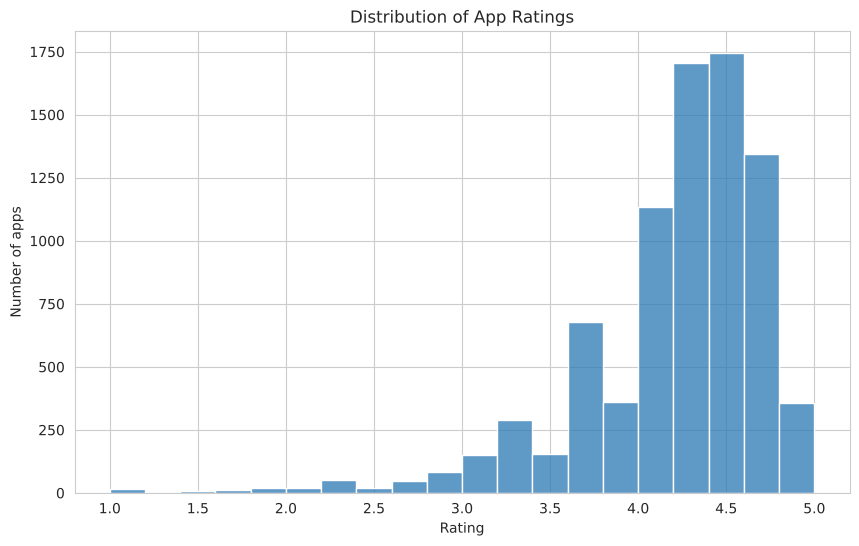

In [45]:
print('Average rating:', round(df_apps['rating'].mean(), 2))
print('Median rating:', df_apps['rating'].median())

sns.histplot(df_apps['rating'], bins=20, color=main_color)
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of apps')
plt.savefig('images/01_rating_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

### Q1: Which category has the highest average rating?
We group the apps by category and calculate the average rating and the number of rated apps. We only keep categories with at least 30 rated apps, because an average of a few apps can be high by chance.

In [46]:
category_rating = df_apps.groupby('category').agg(
    avg_rating=('rating', 'mean'),
    rated_apps=('rating', 'count')
)
category_rating = category_rating.query('rated_apps >= 30')
category_rating = category_rating.sort_values('avg_rating', ascending=False)
print('Categories kept:', len(category_rating))
category_rating.head(10)

Categories kept: 33


,avg_rating,rated_apps
category,,
EVENTS,4.435556,45
ART_AND_DESIGN,4.359322,59
EDUCATION,4.351429,105
BOOKS_AND_REFERENCE,4.344970,169
PERSONALIZATION,4.332215,298
PARENTING,4.300000,50
BEAUTY,4.278571,42
SOCIAL,4.247291,203
GAME,4.244605,899


We draw the top 10 categories as a horizontal bar chart, with the value next to each bar.

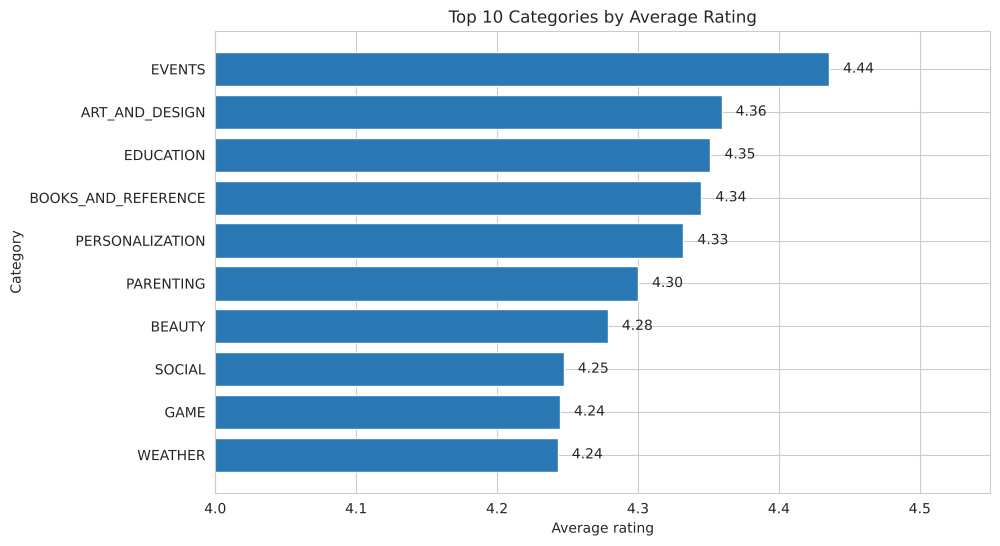

In [47]:
top10_rating = category_rating.head(10).sort_values('avg_rating')

plt.barh(top10_rating.index, top10_rating['avg_rating'], color=main_color)
for i, value in enumerate(top10_rating['avg_rating']):
    plt.text(value + 0.01, i, f'{value:.2f}', va='center')
plt.xlim(4, 4.55)
plt.title('Top 10 Categories by Average Rating')
plt.xlabel('Average rating')
plt.ylabel('Category')
plt.savefig('images/02_q1_top_categories_rating.png', dpi=100, bbox_inches='tight')
plt.show()

**Answer Q1:** EVENTS has the highest average rating (4.44), then ART_AND_DESIGN, EDUCATION and BOOKS_AND_REFERENCE (about 4.35). But the differences are small: the top 10 are all between about 4.24 and 4.44. Note: the x-axis starts at 4 to make the differences visible.

### Q2: Do free apps have more installs than paid apps on average?
We filter the free and paid apps with loc, make a small summary table for each one with the same columns, and join them with concat into one comparison table.

In [48]:
free_apps = df_apps.loc[df_apps['type'] == 'Free']
paid_apps = df_apps.loc[df_apps['type'] == 'Paid']

free_summary = pd.DataFrame({
    'type': ['Free'],
    'apps': [len(free_apps)],
    'mean_installs': [free_apps['installs'].mean()],
    'median_installs': [np.median(free_apps['installs'])],
    'median_rating': [free_apps['rating'].median()],
    'median_price': [free_apps['price'].median()]
})

paid_summary = pd.DataFrame({
    'type': ['Paid'],
    'apps': [len(paid_apps)],
    'mean_installs': [paid_apps['installs'].mean()],
    'median_installs': [np.median(paid_apps['installs'])],
    'median_rating': [paid_apps['rating'].median()],
    'median_price': [paid_apps['price'].median()]
})

type_comparison = pd.concat([free_summary, paid_summary], ignore_index=True)
type_comparison

,type,apps,mean_installs,median_installs,median_rating,median_price
0,Free,8905,8.452012e+06,100000.0,4.3,0.00
1,Paid,754,7.607929e+04,1000.0,4.4,2.99


We compare the median installs of free and paid apps in a bar chart.

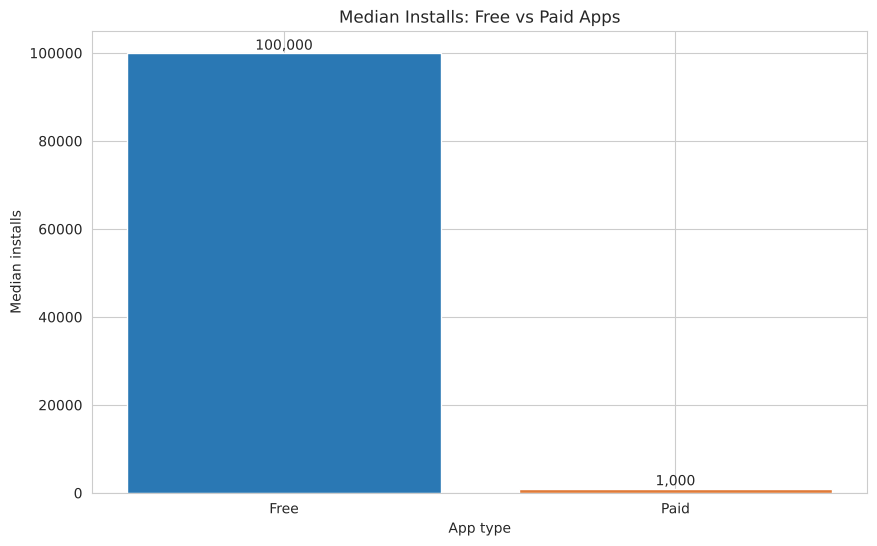

In [49]:
plt.bar(type_comparison['type'], type_comparison['median_installs'], color=['#2a78b4', '#e07b39'])
for i, value in enumerate(type_comparison['median_installs']):
    plt.text(i, value, f'{int(value):,}', ha='center', va='bottom')
plt.title('Median Installs: Free vs Paid Apps')
plt.xlabel('App type')
plt.ylabel('Median installs')
plt.savefig('images/03_q2_free_vs_paid_installs.png', dpi=100, bbox_inches='tight')
plt.show()

A pie chart shows how many apps are free and how many are paid.

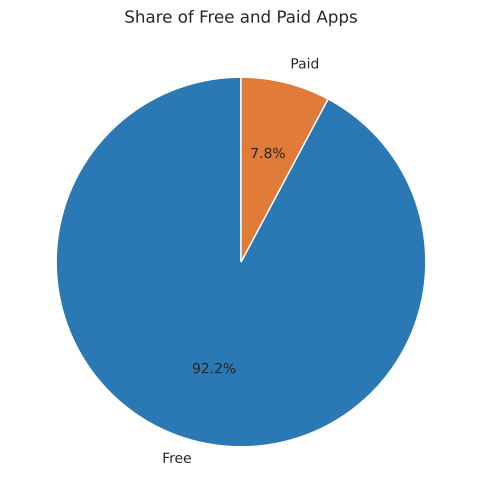

In [50]:
type_counts = df_apps['type'].value_counts()

plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%',
        colors=['#2a78b4', '#e07b39'], startangle=90)
plt.title('Share of Free and Paid Apps')
plt.savefig('images/04_free_paid_share.png', dpi=100, bbox_inches='tight')
plt.show()

A boxplot compares the full spread of ratings for free and paid apps.

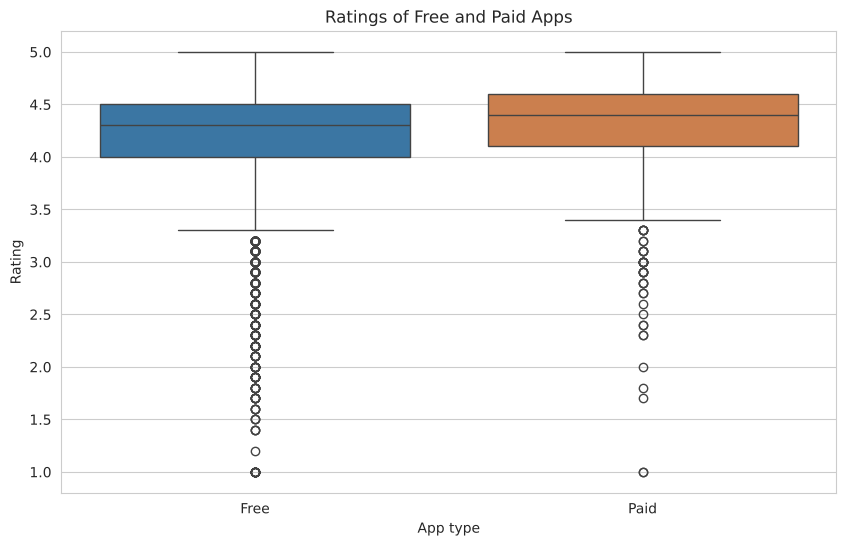

In [51]:
sns.boxplot(data=df_apps, x='type', y='rating', hue='type',
            palette=['#2a78b4', '#e07b39'], legend=False)
plt.title('Ratings of Free and Paid Apps')
plt.xlabel('App type')
plt.ylabel('Rating')
plt.savefig('images/05_rating_by_type_boxplot.png', dpi=100, bbox_inches='tight')
plt.show()

**Answer Q2:** Yes. Free apps have much more installs. The median free app has 100,000+ installs, while the median paid app has only 1,000+ (100 times less). The mean is very different from the median because a few apps have more than 1 billion installs, so the median is better here. Paid apps are only 7.8% of all apps, but their ratings are a little higher (median 4.4 vs 4.3).

### Q3: Do apps updated more recently have higher average ratings?
We group the apps by update_year. We only keep years with at least 30 rated apps (2013 to 2018), because the early years have very few apps.

In [52]:
year_rating = df_apps.groupby('update_year').agg(
    avg_rating=('rating', 'mean'),
    rated_apps=('rating', 'count')
)
year_rating = year_rating.query('rated_apps >= 30')
year_rating

,avg_rating,rated_apps
update_year,,
2013,4.069565,92
2014,4.034783,184
2015,4.064286,378
2016,4.037898,628
2017,4.088553,1424
2018,4.227013,5453


A line chart shows how the average rating changes over the years.

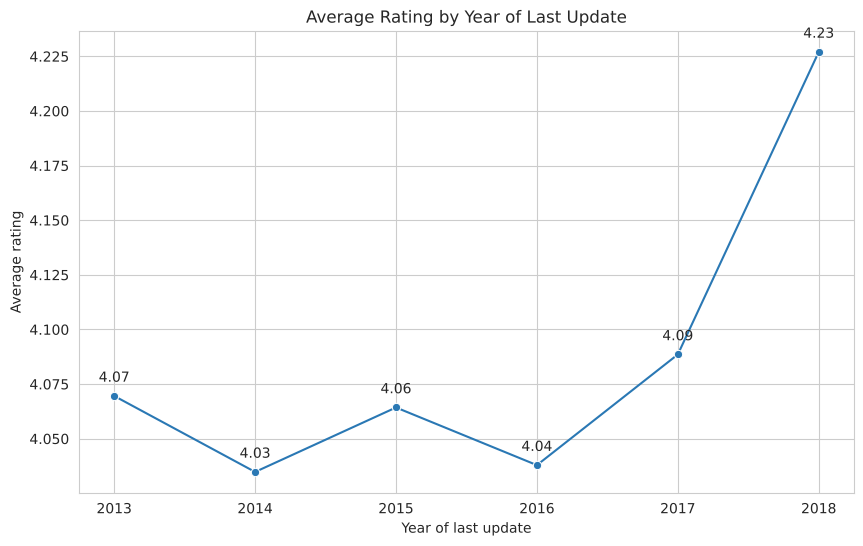

In [53]:
sns.lineplot(x=year_rating.index, y=year_rating['avg_rating'], marker='o', color=main_color)
for year, value in zip(year_rating.index, year_rating['avg_rating']):
    plt.text(year, value + 0.005, round(value, 2), ha='center', va='bottom')
plt.title('Average Rating by Year of Last Update')
plt.xlabel('Year of last update')
plt.ylabel('Average rating')
plt.savefig('images/06_q3_rating_by_update_year.png', dpi=100, bbox_inches='tight')
plt.show()

**Answer Q3:** Mostly yes. Apps last updated in 2018 have the highest average rating (4.23). Apps updated between 2013 and 2017 stay around 4.03 to 4.09. So the clear jump is only for apps that were updated in the same year the data was collected. This is a relationship, not proof that updating causes a better rating.

### Q4: Which category has the highest percentage of positive reviews?
The category is in the apps table and the sentiment is in the reviews table, so we need a merge.

Step 1: we add a column is_positive (1 if the review is positive, else 0), then we summarize the reviews for each app.

In [54]:
df_reviews['is_positive'] = (df_reviews['sentiment'] == 'Positive').astype(int)

review_summary = df_reviews.groupby('app').agg(
    total_reviews=('sentiment', 'count'),
    positive_reviews=('is_positive', 'sum')
).reset_index()

print('Apps with reviews:', len(review_summary))
review_summary.head()

Apps with reviews: 865


,app,total_reviews,positive_reviews
0,10 Best Foods for You,95,79
1,104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,36,27
2,11st,40,23
3,1800 Contacts - Lens Store,40,32
4,1LINE – One Line with One Touch,38,27


Step 2: we merge the review summary with the apps table on the app column. We use an inner merge, because we only want apps that have reviews AND a category. A left merge would add about 8,800 apps with no reviews (NaN).

In [55]:
apps_reviews = pd.merge(df_apps, review_summary, on='app', how='inner')
print('Apps after merge:', len(apps_reviews))
print('Apps lost in the merge:', len(review_summary) - len(apps_reviews))
apps_reviews[['app', 'category', 'total_reviews', 'positive_reviews']].head()

Apps after merge: 816
Apps lost in the merge: 49


,app,category,total_reviews,positive_reviews
0,Facebook,SOCIAL,130,53
1,Clash of Clans,GAME,32,23
2,Clash Royale,GAME,96,58
3,Candy Crush Saga,GAME,40,17
4,8 Ball Pool,GAME,96,48


Step 3: we group by category and calculate the percentage: positive reviews / all reviews * 100. We keep categories with at least 10 apps.

In [56]:
category_sentiment = apps_reviews.groupby('category').agg(
    apps=('app', 'count'),
    total_reviews=('total_reviews', 'sum'),
    positive_reviews=('positive_reviews', 'sum')
)
category_sentiment['positive_pct'] = category_sentiment['positive_reviews'] / category_sentiment['total_reviews'] * 100
category_sentiment = category_sentiment.query('apps >= 10')
category_sentiment = category_sentiment.sort_values('positive_pct', ascending=False)
category_sentiment.head(10)

,apps,total_reviews,positive_reviews,positive_pct
category,,,,
HEALTH_AND_FITNESS,40,1622,1262,77.805179
EDUCATION,19,519,391,75.337187
FOOD_AND_DRINK,18,583,432,74.099485
PERSONALIZATION,34,962,668,69.438669
BOOKS_AND_REFERENCE,16,617,427,69.205835
MEDICAL,33,1156,790,68.339100
PRODUCTIVITY,37,1135,758,66.784141
PHOTOGRAPHY,31,907,589,64.939361
SHOPPING,20,650,420,64.615385


We draw the top 10 categories by percentage of positive reviews.

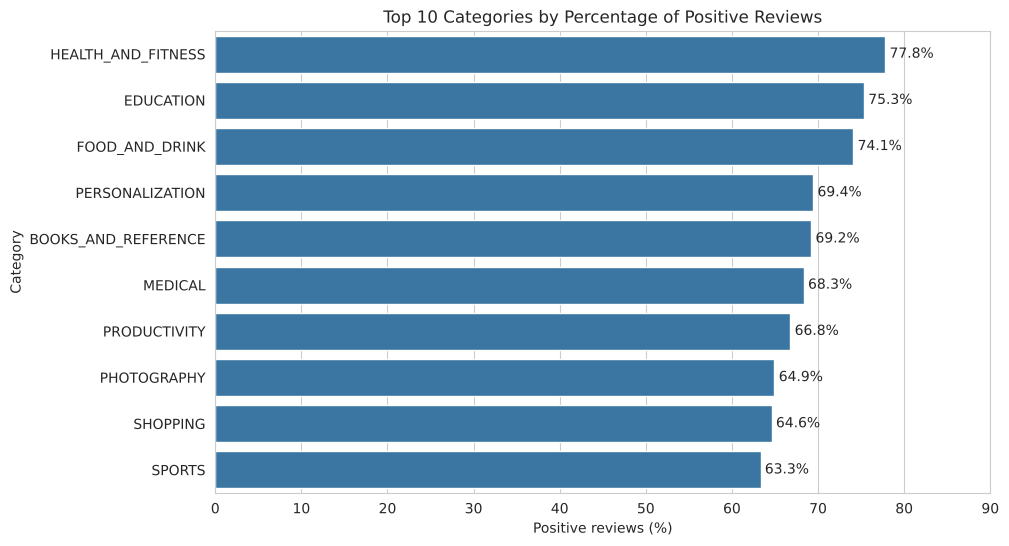

In [57]:
top10_positive = category_sentiment.head(10).reset_index()

sns.barplot(data=top10_positive, x='positive_pct', y='category', color=main_color)
for i, value in enumerate(top10_positive['positive_pct']):
    plt.text(value + 0.5, i, f'{value:.1f}%', va='center')
plt.title('Top 10 Categories by Percentage of Positive Reviews')
plt.xlabel('Positive reviews (%)')
plt.ylabel('Category')
plt.xlim(0, 90)
plt.savefig('images/07_q4_positive_reviews_by_category.png', dpi=100, bbox_inches='tight')
plt.show()

**Answer Q4:** HEALTH_AND_FITNESS has the highest percentage of positive reviews (77.8%), then EDUCATION (75.3%) and FOOD_AND_DRINK (74.1%). The lowest categories are SOCIAL (55.5%), BUSINESS (57.7%) and GAME (58.8%). Note: the reviews file has reviews for only about 800 apps, so this answer is based on a sample, not on all apps.

### Q5: Is there a relationship between app size and number of installs?
First we calculate the correlation (corr) between size_mb and installs, and the skew of each column.

In [58]:
print('Correlation size vs installs:', round(df_apps['size_mb'].corr(df_apps['installs']), 2))
print('Skew of installs:', round(df_apps['installs'].skew(), 2))
print('Skew of size_mb:', round(df_apps['size_mb'].skew(), 2))

Correlation size vs installs: 0.13
Skew of installs: 15.03
Skew of size_mb: 1.65


The correlation is weak (0.13), but installs is very skewed (a few apps have 1 billion installs), so the correlation can hide the pattern. So we also look at the median size for each installs level.

In [59]:
size_by_installs = df_apps.groupby('installs')['size_mb'].median()
size_by_installs

installs
0              5.70
1              9.70
5              9.35
10             8.60
50            11.00
100            8.40
500            6.10
1000           7.90
5000           6.70
10000          8.30
50000          9.90
100000        12.00
500000        15.00
1000000       19.00
5000000       21.50
10000000      25.00
50000000      30.50
100000000     50.00
500000000     50.50
1000000000    44.50
Name: size_mb, dtype: float64

A scatter plot shows every app. We use a log scale for installs because they go from 0 to 1 billion.

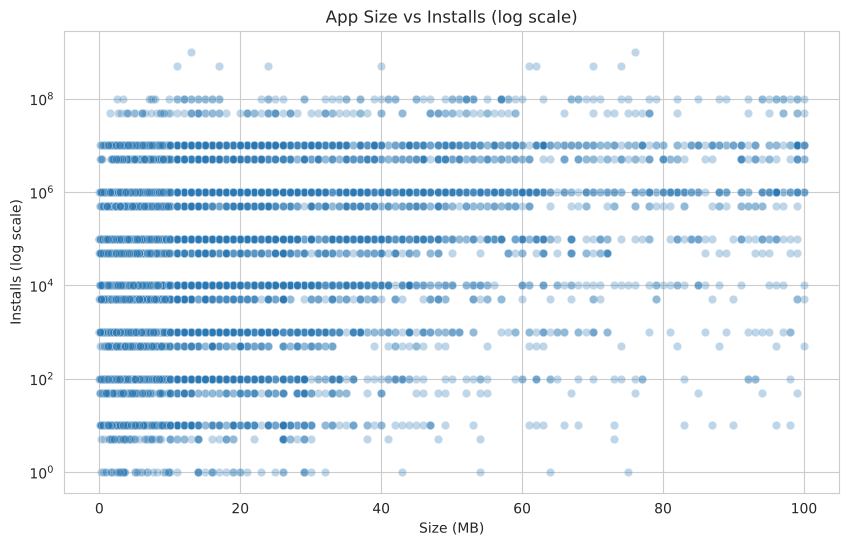

In [60]:
sns.scatterplot(data=df_apps, x='size_mb', y='installs', alpha=0.3, color=main_color)
plt.yscale('log')
plt.title('App Size vs Installs (log scale)')
plt.xlabel('Size (MB)')
plt.ylabel('Installs (log scale)')
plt.savefig('images/08_q5_size_vs_installs.png', dpi=100, bbox_inches='tight')
plt.show()

This line chart shows the median size for each installs level, so the pattern is easier to see.

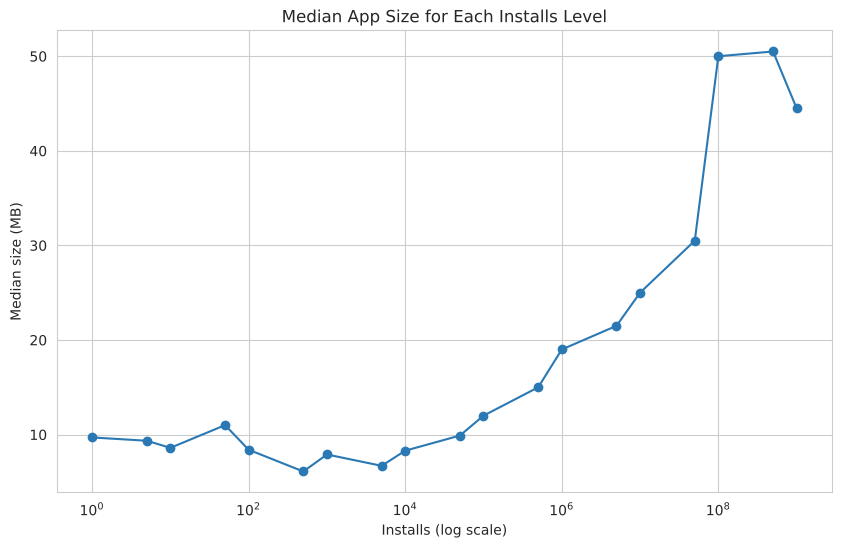

In [61]:
# installs = 0 can't be shown on a log scale, so we skip it
size_by_installs[size_by_installs.index > 0].plot(kind='line', marker='o', logx=True, color=main_color)
plt.title('Median App Size for Each Installs Level')
plt.xlabel('Installs (log scale)')
plt.ylabel('Median size (MB)')
plt.savefig('images/09_q5_median_size_by_installs.png', dpi=100, bbox_inches='tight')
plt.show()

A heatmap shows the correlation between all number columns at once.

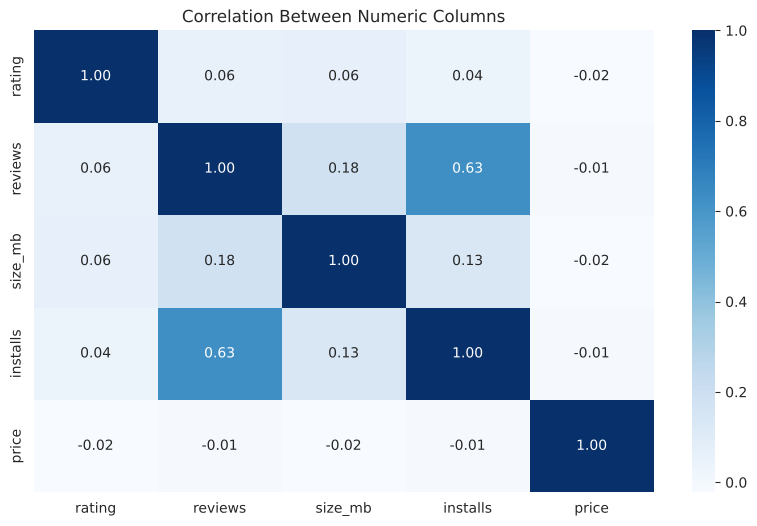

In [62]:
numeric_columns = ['rating', 'reviews', 'size_mb', 'installs', 'price']
sns.heatmap(df_apps[numeric_columns].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title('Correlation Between Numeric Columns')
plt.savefig('images/10_correlation_heatmap.png', dpi=100, bbox_inches='tight')
plt.show()

**Answer Q5:** There is a positive relationship, but it is not a straight line. The correlation is weak (0.13), but the median size grows clearly with installs: apps with less than 100,000 installs are about 6 to 11 MB, while apps with 100 million+ installs are about 45 to 50 MB. A big size does not cause installs; popular apps (like big games and social apps) are usually made by big companies and have more features, so they are bigger. The heatmap also shows that installs is strongly related to reviews (0.63), and rating is almost not related to any number column.

## Draw Conclusions

### Main findings
1. **Free apps get many more installs.** The median free app has 100,000+ installs and the median paid app has only 1,000+. Paid apps are only 7.8% of the store, but they have slightly higher ratings (median 4.4 vs 4.3).
2. **Ratings are high everywhere, so differences are small.** The average rating is about 4.17 (median 4.3). The best categories (EVENTS 4.44, ART_AND_DESIGN, EDUCATION, BOOKS_AND_REFERENCE about 4.35) are only a little above the rest.
3. **Recently updated apps have better ratings.** Apps updated in 2018 have an average rating of 4.23, compared to about 4.03 to 4.09 for apps updated between 2013 and 2017.
4. **Users write the most positive reviews about health, education and food apps.** HEALTH_AND_FITNESS has 77.8% positive reviews, while SOCIAL and GAME are near 55% to 59%.
5. **Popular apps are bigger.** The correlation between size and installs is weak (0.13), but the median size goes from about 8 MB for small apps to about 50 MB for apps with 100 million+ installs.

### Recommendations for a new developer
- Start with a **free** app (with ads or in-app purchases) to reach more users.
- Consider categories with happy users like **Health & Fitness, Education, Books and Personalization**, where ratings and positive reviews are high.
- **Update the app regularly**, because recently updated apps have higher ratings.
- Don't be afraid of a bigger app size if it brings useful features, but a small size alone does not bring installs.

### Limitations
- The data was collected in August 2018, so the results may be different today.
- Installs are ranges (for example "100,000+"), not exact numbers.
- The reviews file covers only about 800 apps (the first 100 reviews of each), so Q4 is based on a sample.
- All results are relationships, not proof of cause and effect.

## Communicate Results
- The project is published on GitHub with this notebook, the raw and clean data, the charts in the images folder, and a README file.
- A short summary with the main charts is shared on LinkedIn.

**Data source:** L. Gupta, "Google Play Store Apps," Kaggle, 2019 (license CC BY-SA 4.0).